<a href="https://colab.research.google.com/github/SMTorg/smt/blob/master/tutorial/Misc/SMT_RMTBUQ_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Uncertainty Quantification with RMTBUQ

<div class="jumbotron text-left"><b>
RMTBUQ extends SMT's RMTB (a regularized, minimal-energy tensor-product
B-spline) with a closed-form Bayesian posterior variance, via the
classical Kimeldorf-Wahba correspondence: a penalized least-squares
spline fit is exactly the posterior mean of a specific Gaussian process.
<div>


**One requirement, not a choice**: `approx_order=2` -- RMTB's own
default (`4`) makes it solve a different, non-quadratic loss for which
the posterior-variance formula does not apply; `RMTBUQ` raises if you
pass anything else. Every example below sets it explicitly.


In [ ]:
# %pip install smt

In [1]:
import math
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import brentq, minimize
from scipy.stats import norm

from smt.surrogate_models import RMTBUQ
from smt.examples.rans_crm_wing.rans_crm_wing import get_rans_crm_wing

%matplotlib inline

### Plotting helpers

Used throughout below; each section's own cells stay fit/predict only.

In [2]:
def plot_band(ax, xq, mean, std, k=2, x_train=None, y_train=None, true=None, title=None):
    """Mean curve, +/-k*std shaded band; optional true curve and training points."""
    if true is not None:
        ax.plot(xq, true, "k--", lw=1, label="true")
    ax.plot(xq, mean, "b", label="mean")
    ax.fill_between(np.ravel(xq), mean - k * std, mean + k * std, color="b", alpha=0.2, label=rf"$\pm{k}\sigma$")
    if x_train is not None:
        ax.plot(x_train, y_train, "ko", ms=5, label="training data")
    if title is not None:
        ax.set_title(title)


def plot_map(fig, ax, X, Y, Z, cmap, title, x_train=None, y_train=None, marker="ko", contour=False):
    """2-D pcolormesh map, optional contour lines and training-point overlay."""
    pcm = ax.pcolormesh(X, Y, Z, cmap=cmap, shading="auto")
    if contour:
        ax.contour(X, Y, Z, 20, colors="k", linewidths=0.4)
    if x_train is not None:
        ax.plot(x_train, y_train, marker, mec="k", ms=4)
    fig.colorbar(pcm, ax=ax)
    ax.set_title(title)


## 1. Regular grid vs. random sampling

Same 1-D noisy function, same number of points, fit once on a regular
grid and once on randomly-placed points.


In [3]:
def toy_fun(x):
    return np.sin(3 * x)


rng = np.random.default_rng(0)
xlimits = np.array([[0.0, 1.0]])
n = 16
noise = 0.05

x_regular = np.linspace(0, 1, n).reshape(-1, 1)
x_random = np.sort(rng.uniform(0, 1, n)).reshape(-1, 1)


In [4]:
xq = np.linspace(0, 1, 300).reshape(-1, 1)

y_train_regular = toy_fun(x_regular) + noise * rng.standard_normal(x_regular.shape)
sm_regular = RMTBUQ(xlimits=xlimits, approx_order=2, print_global=False)
sm_regular.set_training_values(x_regular, y_train_regular)
sm_regular.train()
mean_regular = sm_regular.predict_values(xq).ravel()
std_regular = np.sqrt(sm_regular.predict_variances(xq)).ravel()

y_train_random = toy_fun(x_random) + noise * rng.standard_normal(x_random.shape)
sm_random = RMTBUQ(xlimits=xlimits, approx_order=2, print_global=False)
sm_random.set_training_values(x_random, y_train_random)
sm_random.train()
mean_random = sm_random.predict_values(xq).ravel()
std_random = np.sqrt(sm_random.predict_variances(xq)).ravel()


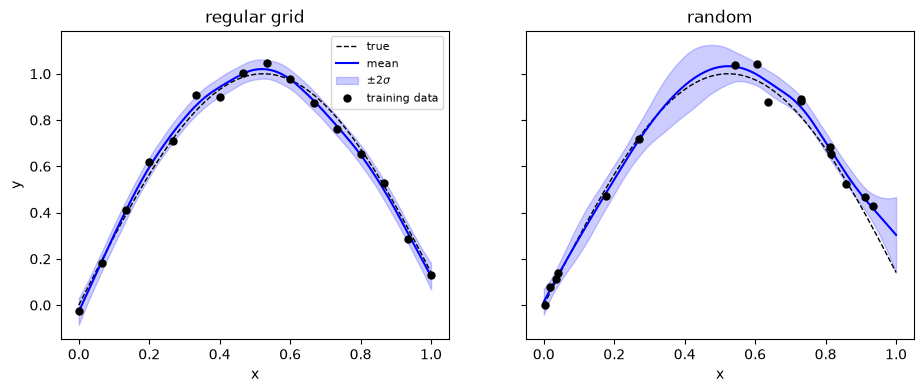

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
plot_band(axs[0], xq, mean_regular, std_regular, x_train=x_regular, y_train=y_train_regular,
          true=toy_fun(xq), title="regular grid")
plot_band(axs[1], xq, mean_random, std_random, x_train=x_random, y_train=y_train_random,
          true=toy_fun(xq), title="random")
axs[0].set(xlabel="x", ylabel="y")
axs[1].set(xlabel="x")
axs[0].legend(fontsize=8)
plt.show()


Both layouts track the data similarly; the uncertainty band pinches near training
points and widens between them, slightly less evenly for the random
layout where gaps are uneven.


## 2. Interpolation vs. smoothing: the `energy_weight` sweep

`energy_weight` is the one knob controlling how closely `RMTB` tracks
noisy data. Small values let it interpolate near-exactly; large values
smooth. At the smallest value below, the posterior variance estimator
has essentially no residual degrees of freedom left -- `RMTBUQ` warns
rather than silently returning an unreliable `sigma2`.


In [6]:
energy_weights = [1e-10, 1e-3, 1e-1]
y_random = toy_fun(x_random) + noise * rng.standard_normal(x_random.shape)

sweep_results = []
for ew in energy_weights:
    # num_ctrl_pts=30 (> n=16): flexible enough that the smallest energy_weight
    # below actually reaches near-exact interpolation and triggers RMTBUQ's own UserWarning
    sm = RMTBUQ(xlimits=xlimits, approx_order=2, num_ctrl_pts=30, energy_weight=ew, print_global=False)
    sm.set_training_values(x_random, y_random)
    sm.train()
    sweep_results.append({
        "energy_weight": ew,
        "edf": sm.edf,
        "sigma2_hat": sm.sigma2[0],
        "mean": sm.predict_values(xq).ravel(),
        "std": np.sqrt(np.clip(sm.predict_variances(xq), 0.0, None)).ravel(),
    })

print(f"sigma2_hat: {[r['sigma2_hat'] for r in sweep_results]}  (true noise variance = {noise ** 2})")


sigma2_hat: [np.float64(0.002244293238567337), np.float64(0.002854547242161338), np.float64(0.04982819605514441)]  (true noise variance = 0.0025000000000000005)


smt/surrogate_models/rmtb_uq.py:320: UserWarning: RMTBUQ: edf=15.1 leaves only dof=n-edf=0.9 residual degrees of freedom out of n=16 training points -- the Wahba sigma2 estimator (RSS / dof) is unreliable this close to exact interpolation. Consider increasing 'energy_weight' and/or 'regularization_weight', reducing 'num_ctrl_pts', or passing a known 'sigma2' directly instead of 'wahba'.
  warnings.warn(


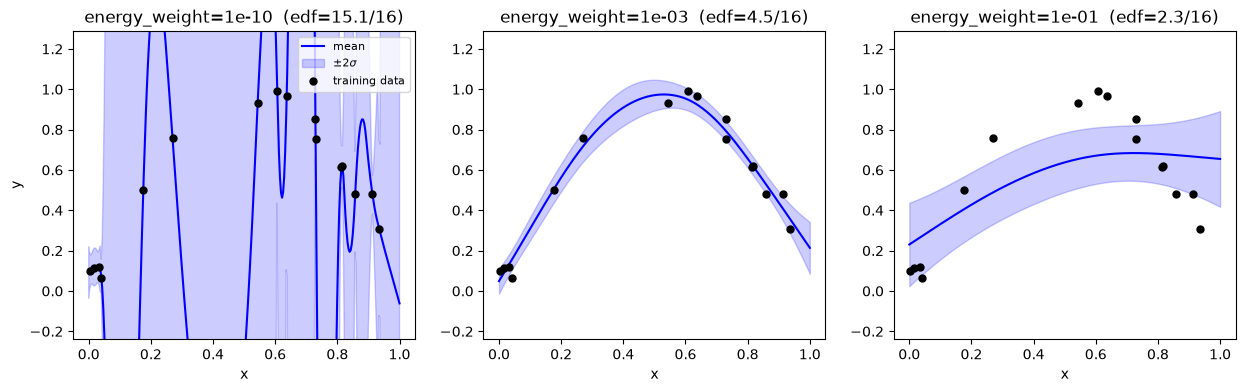

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, r in zip(axs, sweep_results):
    plot_band(ax, xq, r["mean"], r["std"], x_train=x_random, y_train=y_random,
              title=f"energy_weight={r['energy_weight']:.0e}  (edf={r['edf']:.1f}/{n})")
    ax.set_ylim(y_random.min() - 0.3, y_random.max() + 0.3)  # band overflows frame at smallest energy_weight
    ax.set_xlabel("x")
axs[0].set_ylabel("y")
axs[0].legend(fontsize=8)
plt.show()


The warning above is expected, not a bug -- it fires whenever
`energy_weight`/`num_ctrl_pts` leave almost no residual degrees of
freedom (`edf` close to `n`) for the noise estimator.

The printed `sigma2_hat` values make the point concrete: true noise
variance is `0.0025`. At the largest `energy_weight`, `sigma2_hat` is
~20x too large -- the fit is too smooth to track the true function, and
that lack-of-fit gets misattributed as noise. At the smallest
`energy_weight` (`edf` within `1` of `n`), `sigma2_hat` happens to land
close to the true value here, but that is luck, not accuracy: with
almost no residual degrees of freedom left, `RSS/dof` is a ratio of two
near-zero numbers and is not a stable estimate -- re-running with a
different noise draw would move it unpredictably. Only the middle
setting is both close to the true value *and* backed by enough residual
degrees of freedom to trust.


## 3. Selecting `energy_weight` automatically

Section 2 found a safe, accurate `energy_weight` by sweeping three
hand-picked values and judging the result against the DOF warning and
the known true noise level. `energy_weight="auto"` does the same job
without the trial and error: it selects a value via Generalized
Cross-Validation (GCV), restricted to the same DOF-safe region the
warning above already enforces. This costs about one extra matrix
eigendecomposition on top of the ordinary fit, not a refit per
candidate value -- the full derivation is in `docs/TODOs.md`, not
repeated here.


In [8]:
sm_auto = RMTBUQ(xlimits=xlimits, approx_order=2, num_ctrl_pts=30, energy_weight="auto", print_global=False)
sm_auto.set_training_values(x_random, y_random)
sm_auto.train()

mean_auto = sm_auto.predict_values(xq).ravel()
std_auto = np.sqrt(sm_auto.predict_variances(xq)).ravel()
print(f"selected energy_weight: {sm_auto.energy_weight_:.2e}  "
      f"(edf={sm_auto.edf:.1f}/{n}, sigma2_hat={sm_auto.sigma2[0]:.5f}, "
      f"true noise variance={noise ** 2})")


selected energy_weight: 6.92e-06  (edf=9.7/16, sigma2_hat=0.00200, true noise variance=0.0025000000000000005)


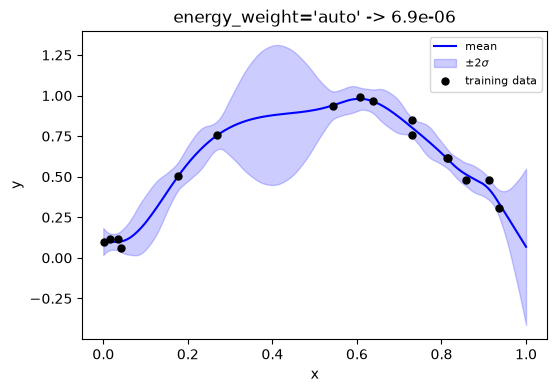

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
plot_band(ax, xq, mean_auto, std_auto, x_train=x_random, y_train=y_random,
          title=f"energy_weight='auto' -> {sm_auto.energy_weight_:.1e}")
ax.set(xlabel="x", ylabel="y")
ax.legend(fontsize=8)
plt.show()


Compare the printed `sigma2_hat` to Section 2's own three values
(`0.00224` at `1e-10`, in the warned near-interpolation regime;
`0.00285` at `1e-3`; `0.0498` at `1e-1`; true noise variance `0.0025`):
`'auto'` lands in the same ballpark as the sweep's own best manual
choice, without having tried three values by hand, and without landing
in the regime the warning exists to catch.


## 4. A real, scattered 2-D dataset

SMT's own `rans_crm_wing` example (angle of attack, Mach number ->
drag coefficient), `n=35`, not on a grid.


In [10]:
xt, yt, rans_xlimits = get_rans_crm_wing()
cd = yt[:, 0]

sm_rans = RMTBUQ(xlimits=rans_xlimits, approx_order=2, num_ctrl_pts=20, print_global=False)
sm_rans.set_training_values(xt, cd)
sm_rans.train()

rad2deg = 180.0 / np.pi
ga, gm = np.meshgrid(np.linspace(-3, 10, 80), np.linspace(0.4, 0.9, 80), indexing="ij")
xq_map = np.column_stack([ga.ravel() / rad2deg, gm.ravel()])

mean_map = sm_rans.predict_values(xq_map).reshape(ga.shape)
std_map = np.sqrt(np.clip(sm_rans.predict_variances(xq_map), 0.0, None)).reshape(ga.shape)


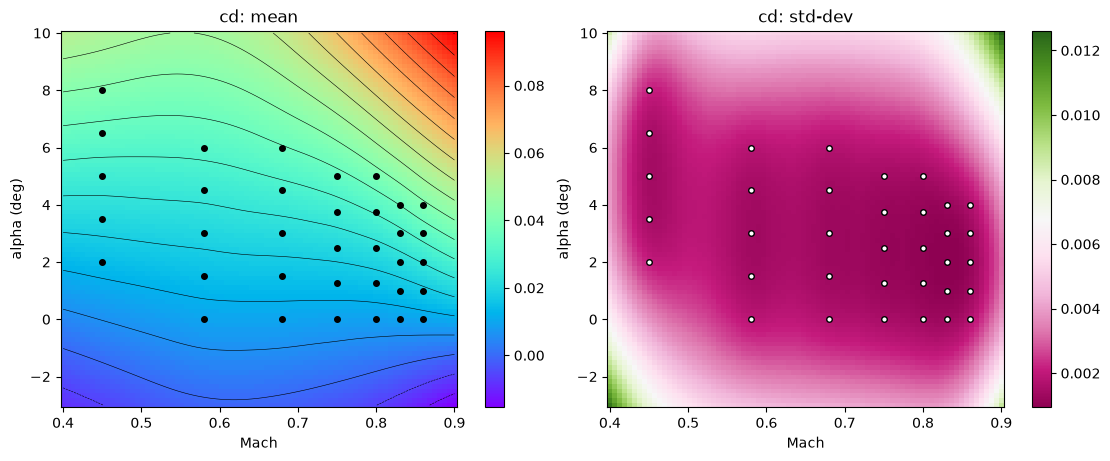

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
plot_map(fig, axs[0], gm, ga, mean_map, "rainbow", "cd: mean",
         x_train=xt[:, 1], y_train=xt[:, 0] * rad2deg, marker="ko", contour=True)
plot_map(fig, axs[1], gm, ga, std_map, "PiYG", "cd: std-dev",
         x_train=xt[:, 1], y_train=xt[:, 0] * rad2deg, marker="wo")
axs[0].set(xlabel="Mach", ylabel="alpha (deg)")
axs[1].set(xlabel="Mach", ylabel="alpha (deg)")
plt.show()


Std-dev is low along the few sampled Mach levels and rises sharply
between them -- the uncertainty surface reflects the data's own sparse
layout, not a generic distance-from-centroid bowl.


## 5. Posterior variance vs. bootstrap variance

A model-agnostic check using only the public API: refit on bootstrap
resamples of the regular-grid dataset from Section 1 and compare the
spread across refits to `RMTBUQ`'s own predicted std. They are not the
same quantity (bootstrap variance of the mean estimator vs. a Bayesian
posterior variance), but they should track each other qualitatively.


In [12]:
y_regular = y_train_regular  # the exact dataset from Section 1, not a fresh noise draw

sm_reg = RMTBUQ(xlimits=xlimits, approx_order=2, print_global=False)
sm_reg.set_training_values(x_regular, y_regular)
sm_reg.train()
model_std = np.sqrt(sm_reg.predict_variances(xq)).ravel()

n_boot = 60
boot_preds = np.full((n_boot, len(xq)), np.nan)
rng_b = np.random.default_rng(1)
for b in range(n_boot):
    idx = rng_b.integers(0, n, n)
    sm_b = RMTBUQ(xlimits=xlimits, approx_order=2, print_global=False)
    sm_b.set_training_values(x_regular[idx], y_regular[idx])
    sm_b.train()
    boot_preds[b] = sm_b.predict_values(xq).ravel()

boot_std = np.nanstd(boot_preds, axis=0)
print(f"correlation: {np.corrcoef(model_std, boot_std)[0, 1]:.2f}")


correlation: 0.65


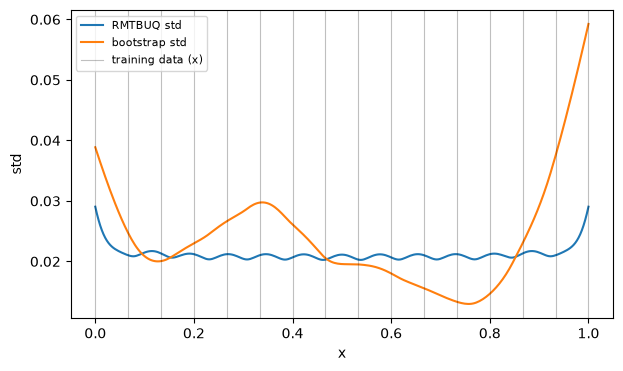

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xq, model_std, label="RMTBUQ std")
ax.plot(xq, boot_std, label="bootstrap std")
for xv in x_regular.ravel():
    ax.axvline(xv, color="k", alpha=0.25, lw=0.8)
ax.set_xlabel("x")
ax.set_ylabel("std")
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color="k", alpha=0.25, lw=0.8, label="training data (x)"))
ax.legend(handles=handles, fontsize=8)
plt.show()


Both curves pinch near training points and grow between them, with a
positive correlation -- the posterior variance is behaving as a genuine
epistemic-uncertainty signal, not an arbitrary number.


### Why `RMTBUQ`'s std has a ripple, and bootstrap's doesn't

$$\mathrm{Var}(x) = \sigma^2 \, f(x)^\top \, \mathrm{mtx}^{-1} \, f(x)$$

`sigma^2` is `RMTBUQ`'s own estimated noise variance (`sm.sigma2`) --
the same Wahba `RSS/dof` estimator from Section 2, including its own
reliability caveats near exact interpolation. It is a single scalar:
the same number for every `x`. That matters here because it means
`sigma^2` can only rescale the *whole* curve up or down uniformly --
it has nothing to do with the ripple's shape. The `x`-dependent shape
comes entirely from the other factor, `f(x)^T mtx^-1 f(x)`.

`f(x)` is `RMTB`'s own B-spline basis row at `x`: only `order` of its
`num_ctrl_pts` entries are nonzero at any given `x`, and *which* ones
are nonzero shifts by one every time `x` crosses a knot (a control-point
boundary) -- a direct consequence of B-splines' compact, local support.
`mtx` is the same regularized normal matrix (`Phi^T Phi` plus the
`energy_weight`/`regularization_weight` penalty terms) `RMTB` already
factors for its own mean fit. Because `f(x)` itself has this knot-tied
rhythm, so does the quadratic form built from it -- one ripple per knot
interval, i.e. roughly `num_ctrl_pts` ripples across the domain,
*regardless of `energy_weight`*.

**What the bootstrap loop above actually varies**: only the *data*.
Every one of its 60 refits uses the exact same `num_ctrl_pts` (and
every other hyperparameter) as the single `RMTBUQ` fit above it --
`RMTBUQ(xlimits=xlimits, approx_order=2, print_global=False)`,
unchanged, every time. What changes, resample to resample, is only
*which* of the 16 original points happen to be included (with repeats)
or left out. There is no mechanism in that loop for a knot-tied ripple
to appear -- the bootstrap curve can only reflect how sensitive the
*fitted mean curve* is to which data points were resampled, a much
coarser signal than the basis's own knot spacing.

The cells below vary `num_ctrl_pts` directly (the thing that actually
controls the ripple) to make this concrete.


In [14]:
num_ctrl_pts_sweep = [8, 15, 30]

ripple_results = []
for ncp in num_ctrl_pts_sweep:
    sm = RMTBUQ(xlimits=xlimits, approx_order=2, num_ctrl_pts=ncp, print_global=False)
    sm.set_training_values(x_regular, y_regular)
    sm.train()
    std = np.sqrt(sm.predict_variances(xq)).ravel()

    # same resampling indices every time (fresh rng_b, same seed as the single bootstrap
    # check above): isolates the effect of num_ctrl_pts from the effect of which points were resampled
    rng_b = np.random.default_rng(1)
    boot_preds = np.full((n_boot, len(xq)), np.nan)
    for b in range(n_boot):
        idx = rng_b.integers(0, n, n)
        sm_b = RMTBUQ(xlimits=xlimits, approx_order=2, num_ctrl_pts=ncp, print_global=False)
        sm_b.set_training_values(x_regular[idx], y_regular[idx])
        sm_b.train()
        boot_preds[b] = sm_b.predict_values(xq).ravel()

    ripple_results.append({
        "num_ctrl_pts": ncp, "std": std, "boot_std": np.nanstd(boot_preds, axis=0),
    })


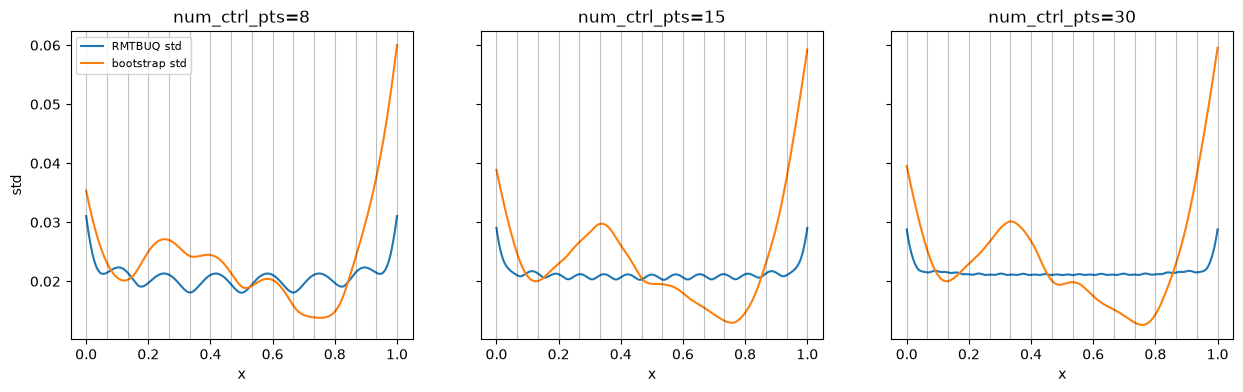

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, r in zip(axs, ripple_results):
    ax.plot(xq, r["std"], label="RMTBUQ std")
    ax.plot(xq, r["boot_std"], label="bootstrap std")
    for xv in x_regular.ravel():
        ax.axvline(xv, color="k", alpha=0.25, lw=0.8)
    ax.set_title(f"num_ctrl_pts={r['num_ctrl_pts']}")
    ax.set_xlabel("x")
axs[0].set_ylabel("std")
axs[0].legend(fontsize=8)
plt.show()


Ripple count scales directly with `num_ctrl_pts` (`~7` ripples at `8`,
`~14` at `15`, `~29` at `30`), and amplitude shrinks as `num_ctrl_pts`
grows -- a finer basis spreads the same regularized precision over more,
smaller local pieces. This confirms the mechanism above rather than
just asserting it: the ripple is a property of the basis's own
granularity, not a bug, and not something `energy_weight` controls.

The bootstrap curve makes the contrast concrete too: using the exact
same resampling indices at every `num_ctrl_pts` (same `rng_b` seed), it
comes out essentially the same curve all three times -- no ripple
appears at any setting. `num_ctrl_pts` changes what `RMTBUQ`'s own
formula reports almost immediately; the bootstrap curve only cares
about the data, and never acquires the basis's texture no matter how
fine or coarse that basis gets.


## 6. A simple Bayesian optimization example

The same 1-D function `SMT_SBO_EGO_Educational.ipynb` optimizes,
reused here to drive point selection by Expected Improvement (EI),
built directly from `predict_values`/`predict_variances` as in that
tutorial -- the same mean+variance mechanism, now powered by `RMTBUQ`
instead of Kriging. Early iterations have very few points, so
`RMTBUQ`'s own near-interpolation warning (Section 2) fires
repeatedly; suppressed here since it's already explained.


In [16]:
def fun_1d(x):
    return (x - 3.5) * np.sin((x - 3.5) / np.pi)


def expected_improvement(sm, points, f_min):
    mean = sm.predict_values(points).ravel()
    std = np.sqrt(np.clip(sm.predict_variances(points), 0.0, None)).ravel()
    with np.errstate(divide="ignore", invalid="ignore"):
        z = (f_min - mean) / std
        ei = (f_min - mean) * norm.cdf(z) + std * norm.pdf(z)
    ei[std < 1e-12] = 0.0
    return ei


bo_xlimits = np.array([[0.0, 25.0]])
x_data = np.array([[0.0], [7.0], [25.0]])
y_data = fun_1d(x_data)
xq_bo = np.linspace(0, 25, 400).reshape(-1, 1)
true_min_bo = fun_1d(xq_bo).ravel().min()
n_iter = 6

bo_results = []
for it in range(n_iter):
    # very few points early on: triggers RMTBUQ's own near-interpolation
    # warning (Section 2) every iteration here, suppressed since it's already explained
    sm = RMTBUQ(xlimits=bo_xlimits, approx_order=2, print_global=False)
    sm.set_training_values(x_data, y_data)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sm.train()

    mean = sm.predict_values(xq_bo).ravel()
    std = np.sqrt(np.clip(sm.predict_variances(xq_bo), 0.0, None)).ravel()

    next_x = None
    if it < n_iter - 1:
        ei = expected_improvement(sm, xq_bo, y_data.min())
        next_x = xq_bo[np.argmax(ei)]

    bo_results.append({
        "x_data": x_data.copy(), "y_data": y_data.copy(),
        "mean": mean, "std": std, "next_x": next_x,
        "error": abs(float(y_data.min()) - true_min_bo),
    })

    if next_x is not None:
        x_data = np.vstack([x_data, next_x.reshape(1, 1)])
        y_data = np.vstack([y_data, fun_1d(next_x).reshape(1, 1)])

print(f"best found: f={y_data.min():.3f} at x={x_data[np.argmin(y_data)].item():.2f}  (true min={true_min_bo:.3f})")


best found: f=-15.125 at x=18.92  (true min=-15.125)


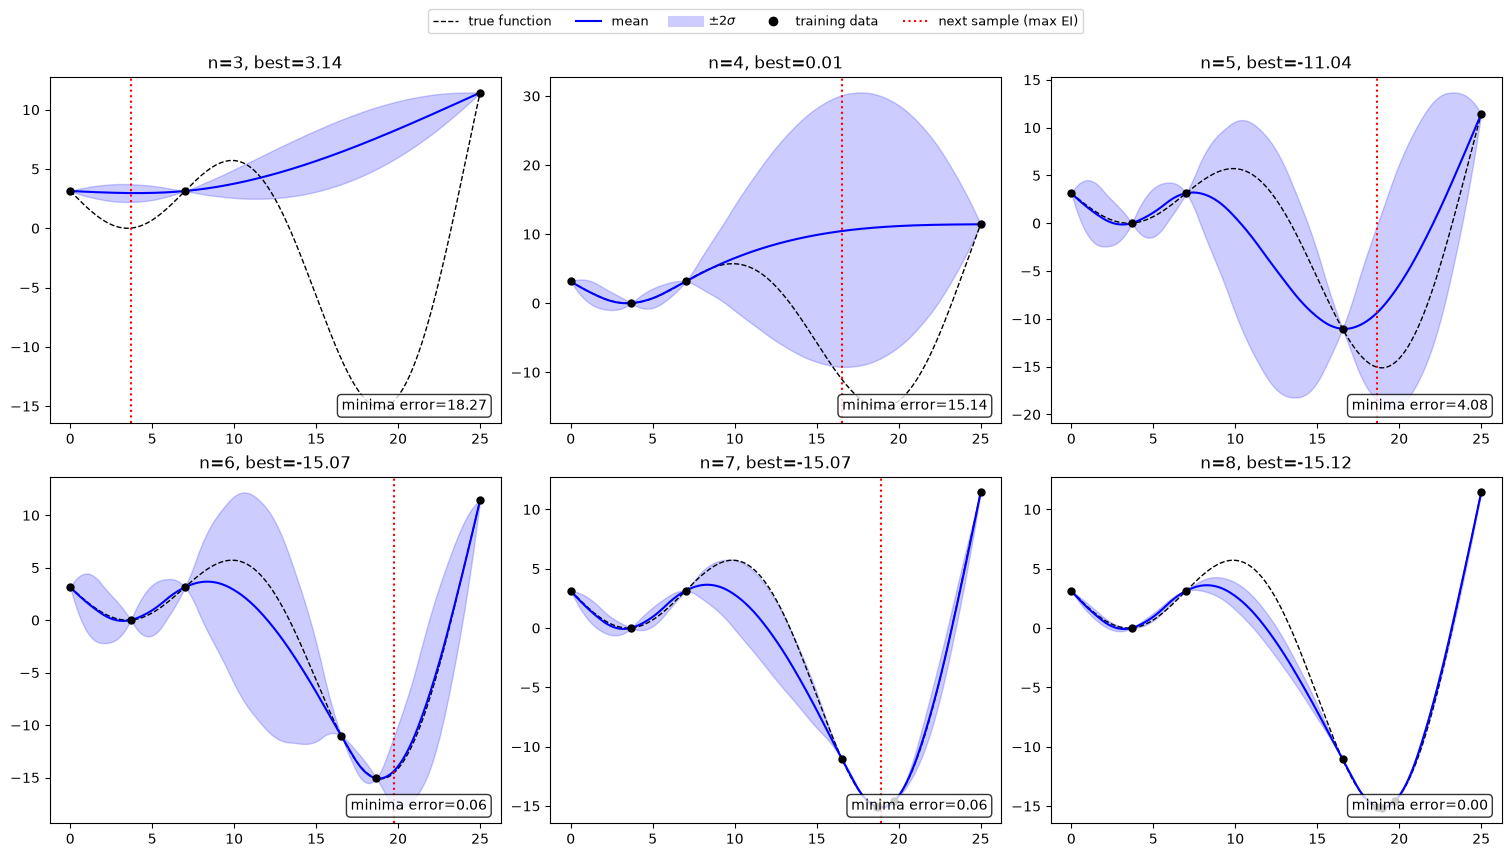

In [17]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for ax, r in zip(axs.flat, bo_results):
    plot_band(ax, xq_bo, r["mean"], r["std"], x_train=r["x_data"], y_train=r["y_data"], true=fun_1d(xq_bo))
    if r["next_x"] is not None:
        ax.axvline(r["next_x"].item(), color="r", ls=":")
    ax.set_title(f"n={len(r['x_data'])}, best={r['y_data'].min():.2f}")
    ax.text(0.97, 0.03, f"minima error={r['error']:.2f}", transform=ax.transAxes, ha="right", va="bottom",
            bbox=dict(boxstyle="round", fc="white", alpha=0.8))

legend_handles = [
    Line2D([0], [0], color="k", ls="--", lw=1, label="true function"),
    Line2D([0], [0], color="b", label="mean"),
    Line2D([0], [0], color="b", alpha=0.2, lw=8, label=r"$\pm2\sigma$"),
    Line2D([0], [0], color="k", marker="o", ls="", label="training data"),
    Line2D([0], [0], color="r", ls=":", label="next sample (max EI)"),
]
fig.legend(handles=legend_handles, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.06), fontsize=9)
plt.show()


EI samples away from the current best where the band is wide, then
tightens around the minimum as points accumulate there -- uncertainty
reduction driving sample placement, the same pattern used in Bayesian
optimization.


## 7. Adaptive sampling to a target RMSE

A different goal from Section 6: not "find the minimum," but
"reconstruct the whole function to a target accuracy," using the same
`fun_1d`/domain/starting DOE. Each iteration samples where `std` is
largest, full stop -- no EI, no mean involved at all. Stops once the
full-domain RMSE (against a dense reference grid; only possible here
because the true function is known) drops below a target.


In [18]:
rmse_target = 0.1
max_iter = 30

x_data_unc = np.array([[0.0], [7.0], [25.0]])
y_data_unc = fun_1d(x_data_unc)
true_vals = fun_1d(xq_bo).ravel()

unc_results = []
for it in range(max_iter):
    sm = RMTBUQ(xlimits=bo_xlimits, approx_order=2, print_global=False)
    sm.set_training_values(x_data_unc, y_data_unc)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sm.train()

    mean = sm.predict_values(xq_bo).ravel()
    std = np.sqrt(np.clip(sm.predict_variances(xq_bo), 0.0, None)).ravel()
    rmse = np.sqrt(np.mean((mean - true_vals) ** 2))

    next_x = None
    if rmse >= rmse_target:
        next_x = xq_bo[np.argmax(std)]

    unc_results.append({
        "n": len(x_data_unc), "rmse": rmse, "mean": mean, "std": std,
        "x_data": x_data_unc.copy(), "y_data": y_data_unc.copy(), "next_x": next_x,
    })

    if next_x is None:
        break

    x_data_unc = np.vstack([x_data_unc, next_x.reshape(1, 1)])
    y_data_unc = np.vstack([y_data_unc, fun_1d(next_x).reshape(1, 1)])

final_unc = unc_results[-1]
ei_rmse = np.sqrt(np.mean((bo_results[-1]["mean"] - true_vals) ** 2))
print(f"uncertainty-sampling: RMSE={final_unc['rmse']:.3f} < {rmse_target} after "
      f"{final_unc['n'] - 3} new samples (n={final_unc['n']}); mean.min={final_unc['mean'].min():.3f}")
print(f"EI (Section 6), for comparison: RMSE={ei_rmse:.3f} after "
      f"{len(bo_results[-1]['x_data']) - 3} new samples (n={len(bo_results[-1]['x_data'])})")


uncertainty-sampling: RMSE=0.071 < 0.1 after 7 new samples (n=10); mean.min=-15.118
EI (Section 6), for comparison: RMSE=1.567 after 5 new samples (n=8)


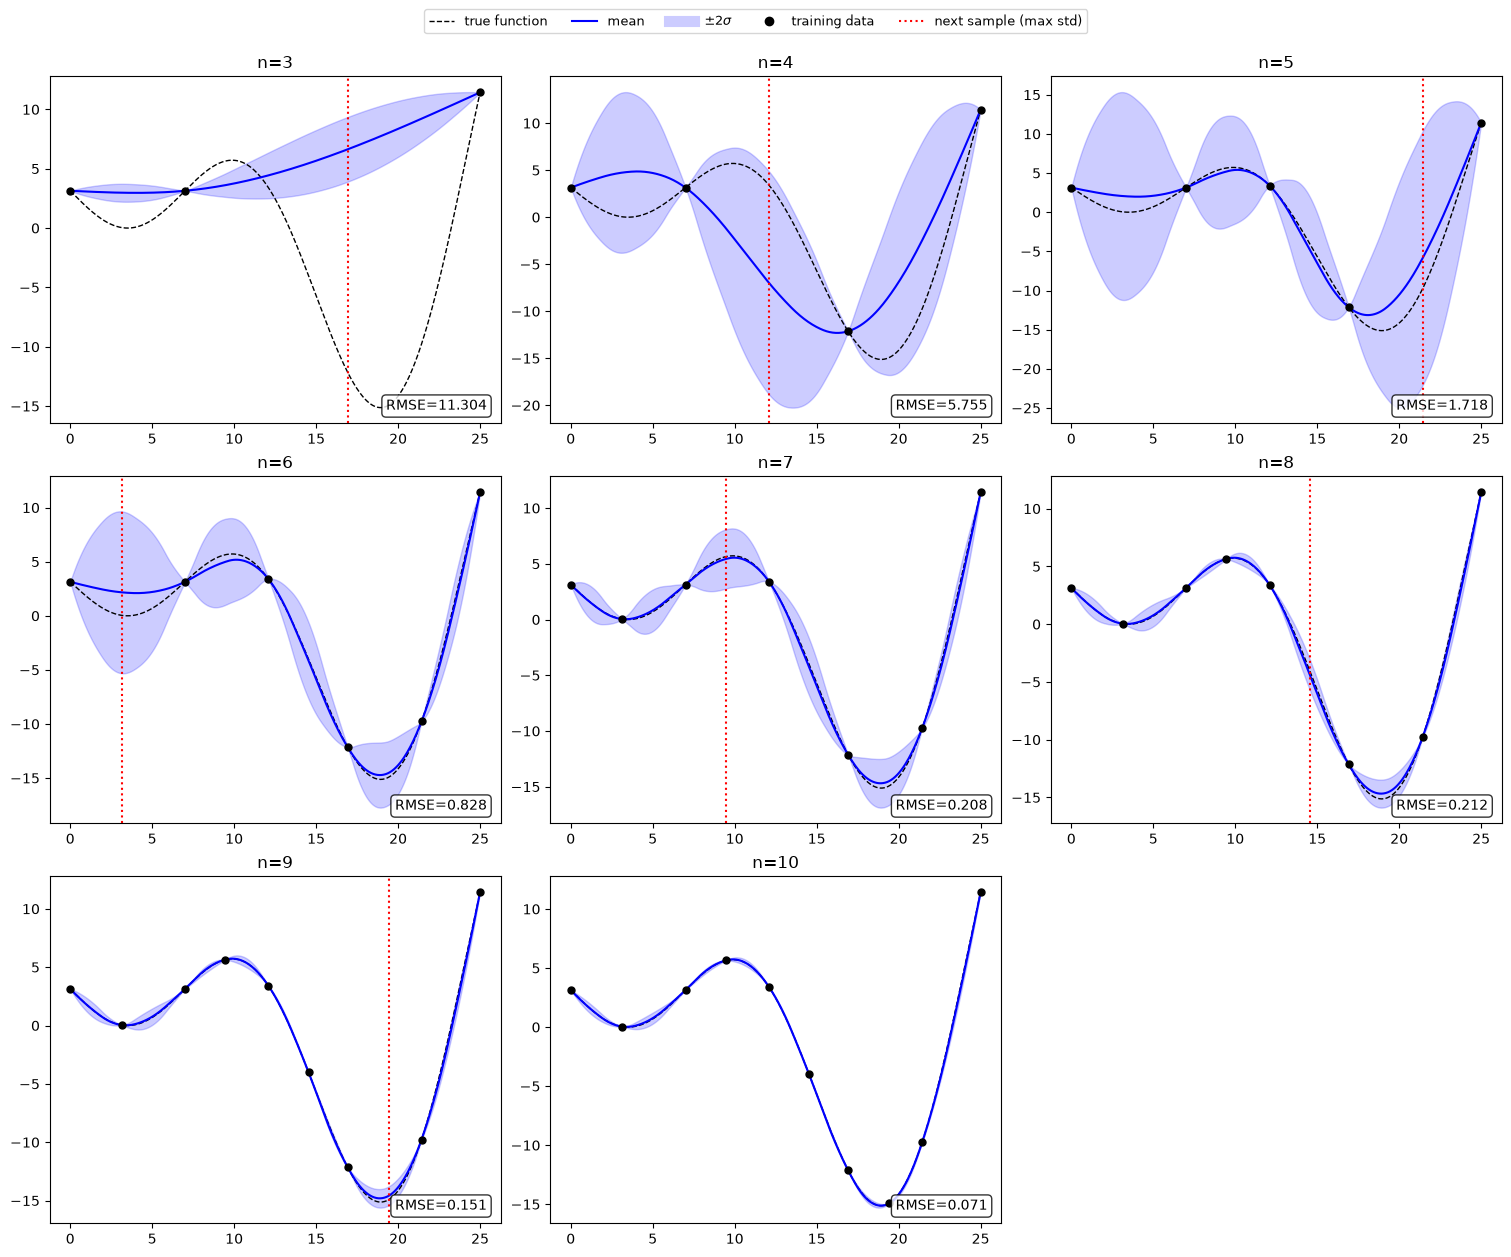

In [19]:
ncols = 2 if len(unc_results) <= 4 else 3
nrows = math.ceil(len(unc_results) / ncols)
fig, axs = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), constrained_layout=True)
for ax, r in zip(axs.flat, unc_results):
    plot_band(ax, xq_bo, r["mean"], r["std"], x_train=r["x_data"], y_train=r["y_data"], true=fun_1d(xq_bo))
    if r["next_x"] is not None:
        ax.axvline(r["next_x"].item(), color="r", ls=":")
    ax.set_title(f"n={r['n']}")
    ax.text(0.97, 0.03, f"RMSE={r['rmse']:.3f}", transform=ax.transAxes, ha="right", va="bottom",
            bbox=dict(boxstyle="round", fc="white", alpha=0.8))
for ax in axs.flat[len(unc_results):]:
    ax.axis("off")

legend_handles = [
    Line2D([0], [0], color="k", ls="--", lw=1, label="true function"),
    Line2D([0], [0], color="b", label="mean"),
    Line2D([0], [0], color="b", alpha=0.2, lw=8, label=r"$\pm2\sigma$"),
    Line2D([0], [0], color="k", marker="o", ls="", label="training data"),
    Line2D([0], [0], color="r", ls=":", label="next sample (max std)"),
]
fig.legend(handles=legend_handles, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.04), fontsize=9)
plt.show()


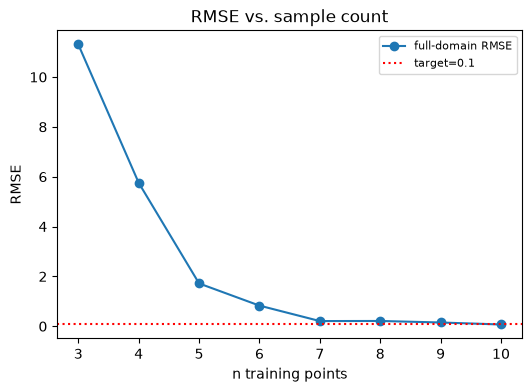

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
ns = [r["n"] for r in unc_results]
rmses = [r["rmse"] for r in unc_results]
ax.plot(ns, rmses, "o-", label="full-domain RMSE")
ax.axhline(rmse_target, color="r", ls=":", label=f"target={rmse_target}")
ax.set(xlabel="n training points", ylabel="RMSE", title="RMSE vs. sample count")
ax.legend(fontsize=8)
plt.show()


Uncertainty-sampling needed `7` new samples (`n=10`) to drive the
full-domain RMSE below `0.1` -- more than EI's `5` (`n=8`) -- but by
then its own view of the minimum (`mean.min` above) is already close to
the true value, as a side effect of resolving the whole domain, not
because it was ever looking for it. EI, in exchange for needing fewer
samples to *locate* the minimum, has a full-domain RMSE an order of
magnitude worse at its own final iteration: it never spent a single
sample anywhere else. Neither result is "better" -- they are solving
different problems, and each spends its samples accordingly.


## 8. Adaptive sampling without a known truth

The realistic version of Sections 6/7: the function is expensive,
noisy, and genuinely unknown. Sampling still uses the same ALM rule as
Section 7 (`argmax(std)`), but the stopping rule can no longer compare
against a ground truth -- it compares the model against *itself*: stop
once the largest remaining epistemic `std` drops to the scale of
`RMTBUQ`'s own estimated noise, `sqrt(sigma2_hat)`. Past that point,
further samples would be resolving noise, not signal. The true curve
is used exactly once at the very end, only to check whether that call
was reasonable -- never during sampling or to decide when to stop.


In [21]:
rng7 = np.random.default_rng(42)
k_stop = 1.0
max_iter7 = 30

x_data7 = np.linspace(0, 1, 4).reshape(-1, 1)
y_data7 = toy_fun(x_data7) + noise * rng7.standard_normal(x_data7.shape)
xq7 = np.linspace(0, 1, 300).reshape(-1, 1)

results7 = []
for it in range(max_iter7):
    sm = RMTBUQ(xlimits=xlimits, approx_order=2, print_global=False)
    sm.set_training_values(x_data7, y_data7)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sm.train()

    mean = sm.predict_values(xq7).ravel()
    std = np.sqrt(np.clip(sm.predict_variances(xq7), 0.0, None)).ravel()
    noise_std = np.sqrt(sm.sigma2[0])
    ratio = std.max() / noise_std  # stopping criterion: 1.0 means epistemic std has shrunk to noise floor

    next_x = None
    if ratio >= k_stop:
        next_x = xq7[np.argmax(std)]

    results7.append({
        "x_data": x_data7.copy(), "y_data": y_data7.copy(),
        "mean": mean, "std": std, "next_x": next_x, "ratio": ratio,
    })

    if next_x is None:
        break

    x_data7 = np.vstack([x_data7, next_x.reshape(1, 1)])
    y_data7 = np.vstack([y_data7, (toy_fun(next_x) + noise * rng7.standard_normal((1, 1))).reshape(1, 1)])

print(f"stopped after {len(x_data7) - 4} new samples (n={len(x_data7)}); "
      f"max(std)/noise_std={results7[-1]['ratio']:.2f}")


stopped after 9 new samples (n=13); max(std)/noise_std=0.95


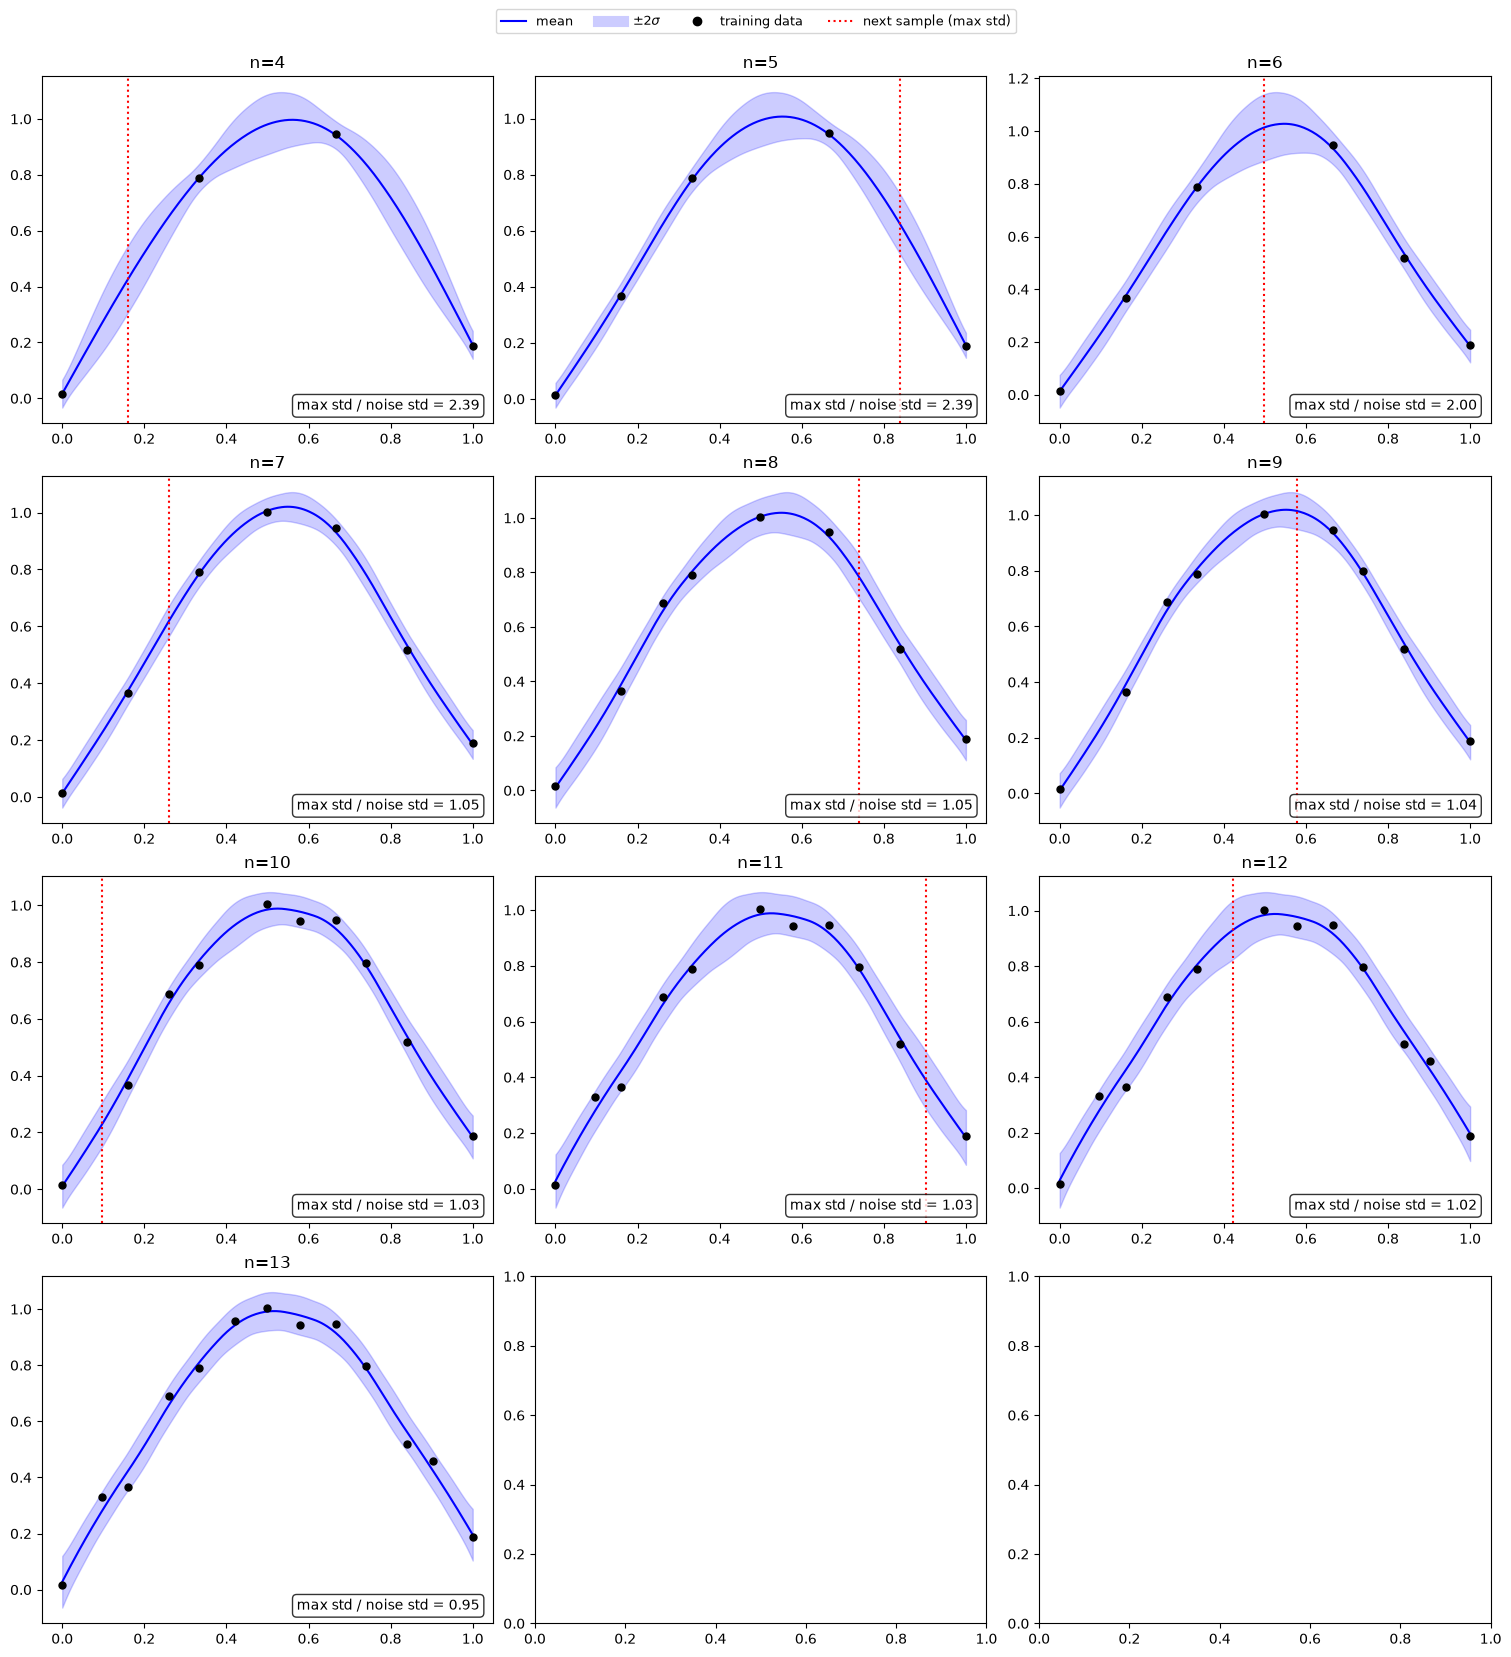

In [22]:
ncols = 2 if len(results7) <= 4 else 3
nrows = math.ceil(len(results7) / ncols)
fig, axs = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), constrained_layout=True)
axs_flat = np.atleast_1d(axs).flat
for ax, r in zip(axs_flat, results7):
    plot_band(ax, xq7, r["mean"], r["std"], x_train=r["x_data"], y_train=r["y_data"])
    if r["next_x"] is not None:
        ax.axvline(r["next_x"].item(), color="r", ls=":")
    ax.set_title(f"n={len(r['x_data'])}")
    ax.text(0.97, 0.03, f"max std / noise std = {r['ratio']:.2f}", transform=ax.transAxes, ha="right", va="bottom",
            bbox=dict(boxstyle="round", fc="white", alpha=0.8))
for ax in list(axs_flat)[len(results7):]:
    ax.axis("off")

legend_handles = [
    Line2D([0], [0], color="b", label="mean"),
    Line2D([0], [0], color="b", alpha=0.2, lw=8, label=r"$\pm2\sigma$"),
    Line2D([0], [0], color="k", marker="o", ls="", label="training data"),
    Line2D([0], [0], color="r", ls=":", label="next sample (max std)"),
]
fig.legend(handles=legend_handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.03), fontsize=9)
plt.show()

`max std / noise std` is the error measure that's actually applicable
here -- no ground truth needed, it's the same ratio driving the
stopping decision, shown on every panel so the reader watches it
converge toward `1.0`. The true function and its RMSE are deliberately
*not* shown yet.


In [23]:
def loo_cv_rmse(xlimits, x, y):
    """Leave-one-out CV RMSE: an independent, oracle-free accuracy proxy --
    not used to decide where to sample or when to stop, only to sanity-check that decision."""
    n = len(x)
    sq_errs = []
    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False
        sm = RMTBUQ(xlimits=xlimits, approx_order=2, print_global=False)
        sm.set_training_values(x[mask], y[mask])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            sm.train()
        pred = sm.predict_values(x[i : i + 1]).ravel()[0]
        sq_errs.append((pred - y[i, 0]) ** 2)
    return np.sqrt(np.mean(sq_errs))


loo_rmses = [loo_cv_rmse(xlimits, r["x_data"], r["y_data"]) for r in results7]


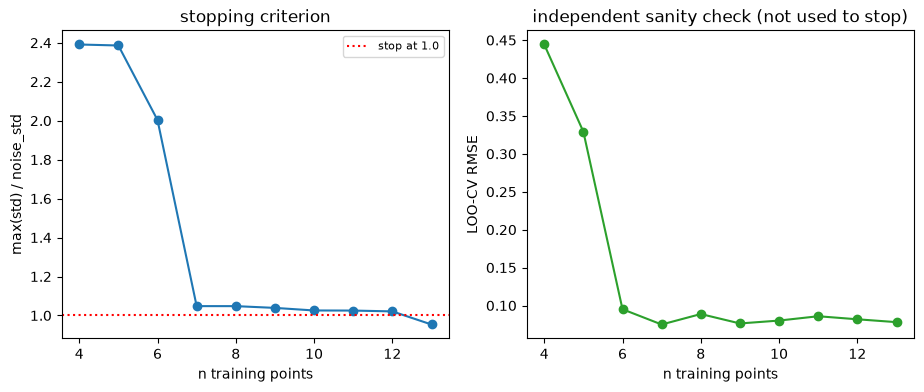

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ns7 = [len(r["x_data"]) for r in results7]
ratios7 = [r["ratio"] for r in results7]

axs[0].plot(ns7, ratios7, "o-")
axs[0].axhline(k_stop, color="r", ls=":", label=f"stop at {k_stop}")
axs[0].set(xlabel="n training points", ylabel="max(std) / noise_std", title="stopping criterion")
axs[0].legend(fontsize=8)

axs[1].plot(ns7, loo_rmses, "o-", color="tab:green")
axs[1].set(xlabel="n training points", ylabel="LOO-CV RMSE", title="independent sanity check (not used to stop)")
plt.show()


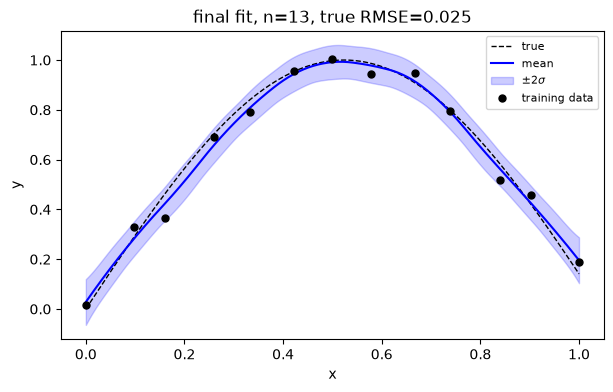

In [25]:
final7 = results7[-1]
true_rmse7 = np.sqrt(np.mean((final7["mean"] - toy_fun(xq7).ravel()) ** 2))

fig, ax = plt.subplots(figsize=(7, 4))
plot_band(ax, xq7, final7["mean"], final7["std"], x_train=final7["x_data"], y_train=final7["y_data"],
          true=toy_fun(xq7), title=f"final fit, n={len(final7['x_data'])}, true RMSE={true_rmse7:.3f}")
ax.set(xlabel="x", ylabel="y")
ax.legend(fontsize=8)
plt.show()


**Revealed only now**: `true RMSE=0.025`, about half the injected
noise level (`0.05`) -- as good as a noisy fit of this function
reasonably gets, reached using nothing but `RMTBUQ`'s own `std` and
`sigma2_hat`. The LOO-CV curve is noisy itself (it is computed from a
handful of points, refit each time), but from `n=7` onward -- where
the stopping ratio is already hovering near `1`, several iterations
before it actually crosses below it -- it settles into the same
`~0.08`-`0.09` range rather than continuing to trend down: a second,
independent signal that sampling further would not have bought much.
Section 7 could *verify* its own stopping decision against a known
truth; this section could only check its decision two ways that don't
require one, and both agreed.


## 9. Gradient-based optimization with UQ: a constrained design problem

A realistic design question on the `rans_crm_wing` data from Section 4:
minimize drag coefficient $C_d$ subject to a required lift coefficient
$C_l = C_{l,\text{target}}$. Unconstrained $C_d$ minimization has no
interior optimum -- it always wants the lowest lift it can get -- and a
raw $C_l/C_d$ ratio is numerically unstable wherever the $C_d$
surrogate's mean approaches zero, so neither is used here.

The objective is a risk-aware upper confidence bound,
$$
J_k(\mathbf{x}) = C_d(\mathbf{x}) + k\,\sigma(\mathbf{x}), \qquad
\frac{d\sigma}{d\mathbf{x}} = \frac{1}{2\sigma}\,\frac{d\,\mathrm{Var}}{d\mathbf{x}},
$$
minimized by `scipy.optimize.minimize`'s `SLSQP` subject to the
equality constraint $C_l(\mathbf{x}) - C_{l,\text{target}} = 0$. Every
gradient involved is exact: the objective's from
`predict_derivatives`/`predict_variance_derivatives`, the constraint's
from `predict_derivatives` on a second model fit to $C_l$ -- no finite
differences anywhere in this section. `SLSQP` is used specifically for
its native handling of the equality constraint, and because
gradient-based local search remains tractable at the much larger
design-variable counts typical of real aerodynamic optimization, where
a grid or EI search (Sections 6-8) stops being affordable.

$k=0$ is the mean-only optimum. A 25-point multi-start locates it, and
that same starting point is reused for every larger $k$, so the
resulting paths can be compared directly; an independent multi-start
is still run for each $k>0$ as a check against the shared start falling
short of that $k$'s own optimum. Two $C_{l,\text{target}}$ values are
compared below: one inside the sampled envelope, one pushed beyond it.


In [26]:
cl = yt[:, 1]

# sm_rans (Cd) is Section 4's own fit, reused as-is; only Cl needs a new model
sm_rans_cl = RMTBUQ(xlimits=rans_xlimits, approx_order=2, num_ctrl_pts=20, print_global=False)
sm_rans_cl.set_training_values(xt, cl)
sm_rans_cl.train()

rans_bounds = [(rans_xlimits[0, 0], rans_xlimits[0, 1]), (rans_xlimits[1, 0], rans_xlimits[1, 1])]


In [27]:
def drag_objective(x, k):
    """Cd(x) + k*std(x) and its exact gradient over (alpha, Mach), via
    d(std)/dx = d(Var)/dx / (2*std). k=0 reduces to the plain mean."""
    xx = np.array([x])
    mean = sm_rans.predict_values(xx).ravel()[0]
    g0 = sm_rans.predict_derivatives(xx, 0).ravel()[0]
    g1 = sm_rans.predict_derivatives(xx, 1).ravel()[0]
    if k == 0.0:
        return mean, np.array([g0, g1])
    var = sm_rans.predict_variances(xx).ravel()[0]
    dvar0 = sm_rans.predict_variance_derivatives(xx, 0).ravel()[0]
    dvar1 = sm_rans.predict_variance_derivatives(xx, 1).ravel()[0]
    std = np.sqrt(max(var, 1e-12))
    dstd0, dstd1 = dvar0 / (2 * std), dvar1 / (2 * std)
    return mean + k * std, np.array([g0 + k * dstd0, g1 + k * dstd1])


def lift_constraint_value(x, cl_target):
    """Cl(x) - cl_target: an equality constraint, zero at the required lift."""
    return sm_rans_cl.predict_values(np.array([x])).ravel()[0] - cl_target


def lift_constraint_jac(x, cl_target):
    xx = np.array([x])
    g0 = sm_rans_cl.predict_derivatives(xx, 0).ravel()[0]
    g1 = sm_rans_cl.predict_derivatives(xx, 1).ravel()[0]
    return np.array([g0, g1])


def run_slsqp(x0, k, cons):
    path = [np.array(x0, dtype=float)]
    run = minimize(
        drag_objective, x0, args=(k,), jac=True, method="SLSQP",
        bounds=rans_bounds, constraints=[cons],
        callback=lambda xk, path=path: path.append(np.array(xk)),
    )
    return run, np.array(path)


def multistart_best(k, cons, cl_target):
    best_res, best_path, best_x0 = None, None, None
    for x0 in opt_starts:
        run, path = run_slsqp(x0, k, cons)
        if run.success and abs(lift_constraint_value(run.x, cl_target)) < 1e-4:
            if best_res is None or run.fun < best_res.fun:
                best_res, best_path, best_x0 = run, path, x0
    return best_res, best_path, best_x0

In [28]:
cl_targets = [0.5, 1.0]  # inside the sampled envelope (0.20-0.82), and pushed beyond it
k_values = [0.0, 10.0, 20.0]  # mean-only, moderate, and strongly risk-averse

rng_opt = np.random.default_rng(0)
opt_starts = [[rng_opt.uniform(*rans_bounds[0]), rng_opt.uniform(*rans_bounds[1])] for _ in range(25)]

opt_results = {}
independent_refs = {}  # k>0 only: the global optimum an independent multi-start would have found
shared_starts = {}
for cl_target in cl_targets:
    cons = {"type": "eq", "fun": lift_constraint_value, "jac": lift_constraint_jac, "args": (cl_target,)}

    # multi-start only for k=0; its winning x0 is then reused for every other k below,
    # so all paths at this Cl_target start from the same point and are directly comparable
    best_res, best_path, shared_x0 = multistart_best(0.0, cons, cl_target)
    opt_results[(cl_target, 0.0)] = (best_res, best_path)
    shared_starts[cl_target] = shared_x0

    for k in k_values:
        if k == 0.0:
            continue
        run, path = run_slsqp(shared_x0, k, cons)
        opt_results[(cl_target, k)] = (run, path)
        # independent reference: what a full 25-start search would have found for this k alone,
        # to check whether the shared-start path above got trapped short of it
        independent_refs[(cl_target, k)] = multistart_best(k, cons, cl_target)[0]

for (cl_target, k), (res, path) in opt_results.items():
    cd_mean = sm_rans.predict_values(np.array([res.x])).ravel()[0]
    cd_std = np.sqrt(sm_rans.predict_variances(np.array([res.x])).ravel()[0])
    print(f"\nCl_target={cl_target}, k={k:5.1f}: alpha={res.x[0]*rad2deg:5.2f}deg  Mach={res.x[1]:.3f}  "
          f"Cd={cd_mean:.5f}  std={cd_std:.5f}  (path length={len(path)})")
    if k > 0.0:
        ref = independent_refs[(cl_target, k)]
        ref_cd = sm_rans.predict_values(np.array([ref.x])).ravel()[0]
        ref_std = np.sqrt(sm_rans.predict_variances(np.array([ref.x])).ravel()[0])
        print(f"    independent global reference: alpha={ref.x[0]*rad2deg:5.2f}deg  Mach={ref.x[1]:.3f}  "
              f"Cd={ref_cd:.5f}  std={ref_std:.5f}")



Cl_target=0.5, k=  0.0: alpha= 3.64deg  Mach=0.445  Cd=0.02104  std=0.00161  (path length=10)

Cl_target=0.5, k= 10.0: alpha= 3.40deg  Mach=0.586  Cd=0.02161  std=0.00135  (path length=7)
    independent global reference: alpha= 2.46deg  Mach=0.816  Cd=0.02326  std=0.00096

Cl_target=0.5, k= 20.0: alpha= 3.40deg  Mach=0.588  Cd=0.02163  std=0.00135  (path length=7)
    independent global reference: alpha= 2.44deg  Mach=0.817  Cd=0.02334  std=0.00095

Cl_target=1.0, k=  0.0: alpha= 9.49deg  Mach=0.576  Cd=0.04607  std=0.00473  (path length=7)

Cl_target=1.0, k= 10.0: alpha= 7.76deg  Mach=0.764  Cd=0.05373  std=0.00313  (path length=13)
    independent global reference: alpha= 7.76deg  Mach=0.764  Cd=0.05374  std=0.00313

Cl_target=1.0, k= 20.0: alpha= 7.46deg  Mach=0.787  Cd=0.05524  std=0.00301  (path length=11)
    independent global reference: alpha= 7.46deg  Mach=0.786  Cd=0.05522  std=0.00301


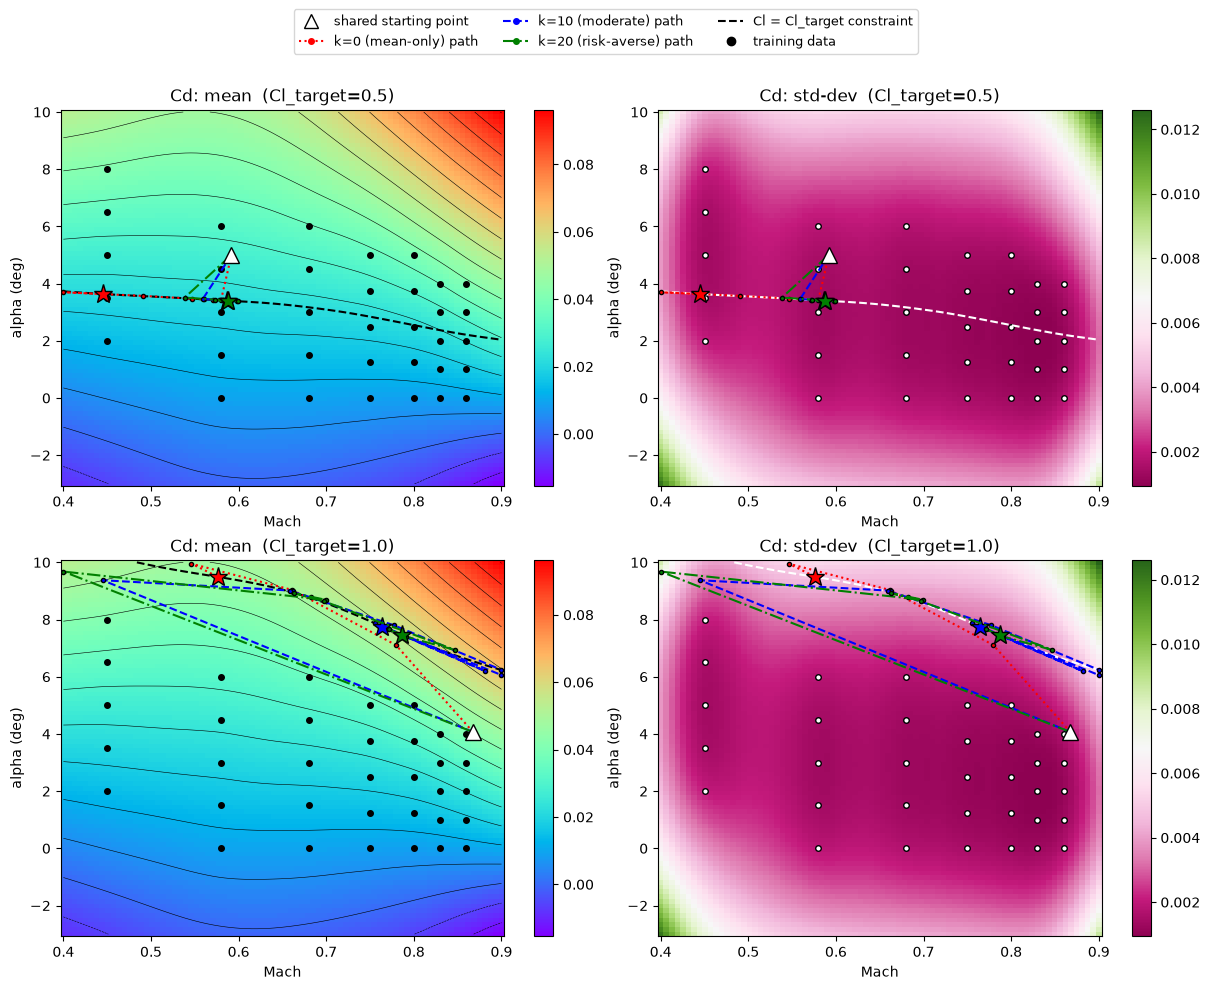

In [29]:
cl_map = sm_rans_cl.predict_values(xq_map).reshape(ga.shape)
path_style = {
    0.0: dict(color="r", ls=":", label="k=0 (mean-only)"),
    10.0: dict(color="b", ls="--", label="k=10 (moderate)"),
    20.0: dict(color="g", ls="-.", label="k=20 (risk-averse)"),
}

fig, axs = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for row, cl_target in enumerate(cl_targets):
    panels = [(mean_map, "rainbow", "Cd: mean", "ko", True), (std_map, "PiYG", "Cd: std-dev", "wo", False)]
    for col, (field, cmap, name, marker, contour) in enumerate(panels):
        ax = axs[row, col]
        plot_map(fig, ax, gm, ga, field, cmap, f"{name}  (Cl_target={cl_target})",
                  x_train=xt[:, 1], y_train=xt[:, 0] * rad2deg, marker=marker, contour=contour)
        ax.contour(gm, ga, cl_map, levels=[cl_target], colors="k" if col == 0 else "w", linewidths=1.5, linestyles="--")
        for k in k_values:
            _, path = opt_results[(cl_target, k)]
            style = path_style[k]
            ax.plot(path[:, 1], path[:, 0] * rad2deg, marker="o", ms=3, mec="k", color=style["color"], ls=style["ls"])
            ax.plot(path[-1, 1], path[-1, 0] * rad2deg, marker="*", ms=14, mec="k", color=style["color"])
        start = shared_starts[cl_target]
        ax.plot(start[1], start[0] * rad2deg, marker="^", ms=12, mfc="white", mec="k", zorder=5)
        ax.set(xlabel="Mach", ylabel="alpha (deg)")

legend_handles = [
    Line2D([0], [0], color="w", marker="^", mec="k", ms=10, ls="", label="shared starting point"),
    Line2D([0], [0], color="r", ls=":", marker="o", ms=4, label="k=0 (mean-only) path"),
    Line2D([0], [0], color="b", ls="--", marker="o", ms=4, label="k=10 (moderate) path"),
    Line2D([0], [0], color="g", ls="-.", marker="o", ms=4, label="k=20 (risk-averse) path"),
    Line2D([0], [0], color="k", ls="--", label="Cl = Cl_target constraint"),
    Line2D([0], [0], color="k", marker="o", ls="", label="training data"),
]
fig.legend(handles=legend_handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.09), fontsize=9)
plt.show()


### Increasing *k* further

An independent multi-start (not the shared start above), for `k` up to
`2000`, to see whether more risk-aversion keeps paying off or only
keeps costing.


In [30]:
cl_target_check = 0.5
cons_check = {"type": "eq", "fun": lift_constraint_value, "jac": lift_constraint_jac, "args": (cl_target_check,)}

for k in [10.0, 20.0, 50.0, 100.0, 500.0, 2000.0]:
    res, _, _ = multistart_best(k, cons_check, cl_target_check)
    cd_mean = sm_rans.predict_values(np.array([res.x])).ravel()[0]
    cd_std = np.sqrt(sm_rans.predict_variances(np.array([res.x])).ravel()[0])
    print(f"k={k:7.1f}: alpha={res.x[0]*rad2deg:5.2f}deg  Mach={res.x[1]:.3f}  Cd={cd_mean:.5f}  std={cd_std:.5f}")


k=   10.0: alpha= 2.46deg  Mach=0.816  Cd=0.02326  std=0.00096
k=   20.0: alpha= 2.44deg  Mach=0.817  Cd=0.02334  std=0.00095
k=   50.0: alpha= 2.44deg  Mach=0.819  Cd=0.02340  std=0.00095
k=  100.0: alpha= 2.43deg  Mach=0.820  Cd=0.02343  std=0.00095
k=  500.0: alpha= 2.32deg  Mach=0.839  Cd=0.02452  std=0.00094
k= 2000.0: alpha= 2.32deg  Mach=0.839  Cd=0.02453  std=0.00094


### Dependence on *energy_weight*

`std` is traced along the same `Cl=0.5` curve at three `energy_weight`
levels, to compare the ripple behind the trap above (Section 5) and
its own absolute scale as the fit moves from near-interpolation to
heavy smoothing (Section 2).


In [31]:
def trace_std_along_cl(energy_weight, cl_target=0.5, n_mach=150):
    """std(Mach) along the Cl=cl_target curve, for a model refit at the given energy_weight."""
    kw = dict(xlimits=rans_xlimits, approx_order=2, num_ctrl_pts=20, energy_weight=energy_weight, print_global=False)
    sm_e_cd = RMTBUQ(**kw)
    sm_e_cd.set_training_values(xt, cd)
    sm_e_cl = RMTBUQ(**kw)
    sm_e_cl.set_training_values(xt, cl)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sm_e_cd.train()
        sm_e_cl.train()

    machs = np.linspace(0.42, 0.88, n_mach)
    stds = []
    for m in machs:
        def f(a, m=m):
            return sm_e_cl.predict_values(np.array([[a, m]])).ravel()[0] - cl_target
        try:
            a_root = brentq(f, rans_xlimits[0, 0], rans_xlimits[0, 1])
        except ValueError:
            stds.append(np.nan)
            continue
        stds.append(np.sqrt(sm_e_cd.predict_variances(np.array([[a_root, m]])).ravel()[0]))
    return machs, np.array(stds), sm_e_cd.edf


for label, ew in [("near-interpolation", 1e-8), ("default/moderate", 1e-4), ("heavily smoothed", 3e-2)]:
    machs, stds, edf = trace_std_along_cl(ew)
    s = stds[~np.isnan(stds)]
    rel_amplitude = (s.max() - s.min()) / s.mean()
    print(f"{label:19s} (energy_weight={ew:.0e}): edf={edf:4.1f}/35  "
          f"std range=[{s.min():.5f}, {s.max():.5f}]  relative amplitude={rel_amplitude:.2f}")


near-interpolation  (energy_weight=1e-08): edf=34.9/35  std range=[0.00006, 0.00310]  relative amplitude=2.78
default/moderate    (energy_weight=1e-04): edf= 9.9/35  std range=[0.00094, 0.00259]  relative amplitude=1.17
heavily smoothed    (energy_weight=3e-02): edf= 4.2/35  std range=[0.00210, 0.01012]  relative amplitude=1.22


| Cl_target | k | alpha (deg) | Mach | Cd | std | reference std |
|---|---|---|---|---|---|---|
| 0.5 | 0 | 3.64 | 0.445 | 0.02104 | 0.00161 | -- |
| 0.5 | 10 | 3.40 | 0.586 | 0.02161 | 0.00135 | 0.00096 |
| 0.5 | 20 | 3.40 | 0.588 | 0.02163 | 0.00135 | 0.00095 |
| 1.0 | 0 | 9.49 | 0.576 | 0.04607 | 0.00473 | -- |
| 1.0 | 10 | 7.76 | 0.764 | 0.05373 | 0.00313 | 0.00313 |
| 1.0 | 20 | 7.46 | 0.787 | 0.05524 | 0.00301 | 0.00301 |

At $C_{l,\text{target}}=0.5$, the mean-only optimum already sits close
to real data; $k=10$ and $k=20$ both stop at the same point,
$\sigma=0.00135$. Tracing $\sigma(\mathbf{x})$ along the constraint
curve shows why: a local minimum there is immediately followed by a
small local maximum ($\mathrm{Mach}=0.635$, $\sigma=0.00151$) before
the true minimum near $\mathrm{Mach}=0.84$
($\sigma\approx0.00094$-$0.00095$, matching the reference column). A
local solver such as `SLSQP` has no way to see past that small rise.

At $C_{l,\text{target}}=1.0$, pushed beyond the sampled $C_l$ range, no
such rise lies between the shared start and the optimum, and both
$k=10$ and $k=20$ already match their independent reference.

Increasing $k$ does not increase the risk of this trap -- $k=10$ and
$k=20$ are caught by the same ripple here. What it does cost is visible
in an independent search up to $k=2000$: past $k\approx20$, $C_d$ keeps
rising ($0.0233\to0.0245$) while $\sigma$ barely falls further
($0.00095\to0.00094$), bounded below by the data's own noise floor.
Beyond that point, $k$ stops trading performance for trustworthiness
and simply pins the design to the single most-certain point in the
domain.

### Do *k* and *energy_weight* need to be chosen together?

Yes, and the reason is structural rather than incidental. The trap
above exists because $\sigma(\mathbf{x})$ inherits the basis's own
knot-tied ripple (Section 5), and how pronounced that ripple is
depends directly on `energy_weight`. Near exact interpolation, the fit
is pulled tightly onto every training point, so $\sigma$ collapses to
almost nothing exactly there and rises sharply in between -- a
landscape of narrow, steep-walled dimples, one per data point. That is
precisely the terrain a local, gradient-based search is most likely to
get caught in: whichever dimple it starts near, it has no way to tell
that a deeper one lies just past a small rise, for any $k$ large
enough to feel the dimples at all.

Smoothing the fit does not simply make $k$ irrelevant, because it
changes two things at once. The ripples themselves do flatten
and spread out -- a smoother basis has fewer effective degrees of
freedom, so there are fewer, broader bumps to get trapped in, which is
a genuine reduction in local-optimum risk. But smoothing also biases
$\sigma$ upward overall: a fit too smooth to track the real data
starts mistaking its own lack of fit for noise, the same mechanism
Section 2 already showed for the noise estimate itself, so the whole
$\sigma$ surface sits higher than it should. A $k$ calibrated to feel
appropriately cautious against one `energy_weight`'s sense of scale
can end up negligible or overwhelming against another's, even before
the ripple shape changes at all.

So the two cannot be tuned independently. `energy_weight` sets both
the texture of the uncertainty landscape -- how trap-prone it is --
and its overall scale -- how much weight a given $k$ actually carries
-- while $k$ only means something relative to whatever that landscape
already looks like. The practical order is to settle `energy_weight`
first, ideally via `energy_weight="auto"` (Section 3) so it isn't a
guess, and only then choose $k$ against the resulting, already-fixed
uncertainty surface.
